Семинар 5. Квантизация MobileNetV2

Модель с весами IMAGENET1K_V1 оценивается на Imagenette без дообучения. Top-1 считается по всем 1000 классам ImageNet. Из train взяты 512 изображений для калибровки и ещё 500 для анализа чувствительности. Для теста используются все 3925 изображений из val.

In [1]:
import os, io, time, copy, tarfile, urllib.request, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchvision
from torchvision import transforms
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
torch.manual_seed(0)
np.random.seed(0)
NUM_THREADS = os.cpu_count()
torch.set_num_threads(NUM_THREADS)
pd.set_option("display.width", 200)
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| CPU threads", NUM_THREADS)
print("CUDA:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "нет")

torch 2.12.1+cu130 | torchvision 0.27.1+cu130 | CPU threads 6
CUDA: NVIDIA RTX A6000


Данные

In [2]:
DATA_DIR = Path(os.environ.get("IMAGENETTE_DIR", "imagenette2-320"))
URL = "https://s3.amazonaws.com/fast-ai-imageclas/imagenette2-320.tgz"
if not DATA_DIR.exists():
    urllib.request.urlretrieve(URL, "imagenette2-320.tgz")
    with tarfile.open("imagenette2-320.tgz") as tar:
        tar.extractall(DATA_DIR.parent if DATA_DIR.parent != Path("") else ".")

WNID_TO_IMAGENET = {
    "n01440764": 0, "n02102040": 217, "n02979186": 482, "n03000684": 491, "n03028079": 497,
    "n03394916": 566, "n03417042": 569, "n03425413": 571, "n03445777": 574, "n03888257": 701,
}
tf = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224), transforms.PILToTensor()])

def load_split(split, indices=None):
    """Грузит картинки в uint8-тензор [N,3,224,224] (нормализация делается на лету)."""
    ds = torchvision.datasets.ImageFolder(DATA_DIR / split, transform=tf)
    to_imagenet = torch.tensor([WNID_TO_IMAGENET[c] for c in ds.classes])
    if indices is not None:
        ds = torch.utils.data.Subset(ds, indices)
    loader = torch.utils.data.DataLoader(ds, batch_size=128, num_workers=NUM_THREADS)
    xs, ys = zip(*loader)
    return torch.cat(xs), to_imagenet[torch.cat(ys)]

n_train = len(torchvision.datasets.ImageFolder(DATA_DIR / "train"))
perm = torch.randperm(n_train, generator=torch.Generator().manual_seed(0)).tolist()
X_calib, y_calib = load_split("train", perm[:512])
X_dev, y_dev = load_split("train", perm[512:1012])
X_test, y_test = load_split("val")
print(f"calib {tuple(X_calib.shape)} | dev {tuple(X_dev.shape)} | test {tuple(X_test.shape)}")

calib (512, 3, 224, 224) | dev (500, 3, 224, 224) | test (3925, 3, 224, 224)


In [3]:
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

def to_float(x_u8):
    return (x_u8.float() / 255.0 - MEAN) / STD

@torch.inference_mode()
def predict(fn, X, bs=64):
    """fn: float-тензор [B,3,224,224] -> логиты [B,1000] (torch или numpy)."""
    out = []
    for i in range(0, len(X), bs):
        o = fn(to_float(X[i:i + bs]))
        out.append(torch.as_tensor(np.asarray(o) if not torch.is_tensor(o) else o).float().cpu())
    return torch.cat(out)

def top1(logits, y):
    return (logits.argmax(1) == y).float().mean().item() * 100

def sqnr(ref, x):
    """Signal-to-quantization-noise ratio логитов относительно fp32, дБ (больше = ближе к fp32)."""
    return (20 * torch.log10(ref.norm() / (ref - x).norm())).item()

def model_size_mb(model):
    buf = io.BytesIO()
    torch.save(model.state_dict(), buf)
    return buf.tell() / 2**20

Исходная модель FP32

In [4]:
float_model = torchvision.models.mobilenet_v2(weights="IMAGENET1K_V1").eval()
fp32_test_logits = predict(float_model, X_test)
fp32_dev_logits = predict(float_model, X_dev)
FP32_ACC = top1(fp32_test_logits, y_test)
FP32_DEV_ACC = top1(fp32_dev_logits, y_dev)
print(f"FP32: test top-1 = {FP32_ACC:.2f}% | dev top-1 = {FP32_DEV_ACC:.2f}% | size = {model_size_mb(float_model):.2f} MB")

FP32: test top-1 = 78.80% | dev top-1 = 80.00% | size = 13.60 MB


Статическая квантизация в PyTorch FX

Сравним способы оценки диапазона активаций, схемы квантизации активаций и весов и размер калибровочной выборки.

In [5]:
from torch.ao.quantization import QConfig, QConfigMapping
from torch.ao.quantization.observer import (
    MinMaxObserver, MovingAverageMinMaxObserver, HistogramObserver, PerChannelMinMaxObserver,
)
from torch.ao.quantization.quantize_fx import prepare_fx, convert_fx

torch.backends.quantized.engine = "x86"
EXAMPLE_INPUTS = (torch.randn(1, 3, 224, 224),)
ACT_OBSERVERS = {"minmax": MinMaxObserver, "movavg": MovingAverageMinMaxObserver, "histogram": HistogramObserver}

def make_qconfig(act_obs="histogram", act_scheme="affine", w_gran="per_channel", w_scheme="symmetric"):
    act_qs = torch.per_tensor_affine if act_scheme == "affine" else torch.per_tensor_symmetric
    act = ACT_OBSERVERS[act_obs].with_args(dtype=torch.quint8, qscheme=act_qs, reduce_range=True)
    if w_gran == "per_channel":
        w_qs = torch.per_channel_symmetric if w_scheme == "symmetric" else torch.per_channel_affine
        weight = PerChannelMinMaxObserver.with_args(dtype=torch.qint8, qscheme=w_qs)
    else:
        w_qs = torch.per_tensor_symmetric if w_scheme == "symmetric" else torch.per_tensor_affine
        weight = MinMaxObserver.with_args(dtype=torch.qint8, qscheme=w_qs)
    return QConfig(activation=act, weight=weight)

@torch.inference_mode()
def ptq(qconfig_mapping, n_calib=256, calib_bs=32, model=float_model):
    m = prepare_fx(copy.deepcopy(model).eval(), qconfig_mapping, EXAMPLE_INPUTS)
    for i in range(0, n_calib, calib_bs):
        m(to_float(X_calib[i:min(i + calib_bs, n_calib)]))
    return convert_fx(m)

def evaluate(qmodel, X=X_test, y=y_test, ref=fp32_test_logits):
    logits = predict(qmodel, X)
    return top1(logits, y), sqnr(ref, logits)

In [6]:
experiments = [
    ("observer акт.", "MinMax", dict(act_obs="minmax"), 256),
    ("observer акт.", "MovingAverageMinMax", dict(act_obs="movavg"), 256),
    ("observer акт.", "Histogram", dict(act_obs="histogram"), 256),
    ("схема акт.", "symmetric (Histogram)", dict(act_scheme="symmetric"), 256),
    ("веса", "per-tensor symmetric", dict(w_gran="per_tensor", w_scheme="symmetric"), 256),
    ("веса", "per-tensor affine", dict(w_gran="per_tensor", w_scheme="affine"), 256),
    ("веса", "per-channel affine", dict(w_gran="per_channel", w_scheme="affine"), 256),
    ("калибровка", "8 картинок", dict(), 8),
    ("калибровка", "32 картинки", dict(), 32),
    ("калибровка", "128 картинок", dict(), 128),
    ("калибровка", "512 картинок", dict(), 512),
]
hp_rows = [dict(Группа="—", Конфигурация="FP32", **{"Top-1, %": FP32_ACC, "Δ, п.п.": 0.0, "SQNR логитов, дБ": np.inf})]
for group, name, kw, n_calib in experiments:
    t0 = time.time()
    try:
        qm = ptq(QConfigMapping().set_global(make_qconfig(**kw)), n_calib=n_calib)
        acc, s = evaluate(qm)
    except Exception as e:
        print(f"{group} / {name}: НЕ поддерживается -> {type(e).__name__}: {str(e)[:120]}")
        acc, s = np.nan, np.nan
    hp_rows.append({"Группа": group, "Конфигурация": name, "Top-1, %": acc, "Δ, п.п.": acc - FP32_ACC,
                    "SQNR логитов, дБ": s})
    print(f"{group:14s} | {name:24s} | top-1 {acc:6.2f}% | SQNR {s:5.1f} dB | {time.time() - t0:5.1f}s")

observer акт.  | MinMax                   | top-1  65.38% | SQNR   2.9 dB |  21.5s


observer акт.  | MovingAverageMinMax      | top-1  70.50% | SQNR   4.1 dB |  20.2s


observer акт.  | Histogram                | top-1  71.52% | SQNR   3.9 dB |  29.4s


схема акт.     | symmetric (Histogram)    | top-1  55.39% | SQNR   3.5 dB |  24.7s


веса           | per-tensor symmetric     | top-1  68.10% | SQNR   2.6 dB |  24.2s


веса           | per-tensor affine        | top-1  71.59% | SQNR   3.8 dB |  24.5s


веса           | per-channel affine       | top-1  71.31% | SQNR   3.8 dB |  25.3s


калибровка     | 8 картинок               | top-1  77.38% | SQNR   9.1 dB |  17.3s


калибровка     | 32 картинки              | top-1  74.45% | SQNR   4.8 dB |  18.3s


калибровка     | 128 картинок             | top-1  74.80% | SQNR   6.5 dB |  21.2s


калибровка     | 512 картинок             | top-1  71.92% | SQNR   5.4 dB |  32.5s


Базовый вариант использует HistogramObserver для активаций (quint8, per-tensor affine) и симметричную поканальную квантизацию весов (qint8). Для калибровки взяты 256 изображений.

In [7]:
hp_df = pd.DataFrame(hp_rows)
hp_df.round(2)

,Группа,Конфигурация,"Top-1, %","Δ, п.п.","SQNR логитов, дБ"
0,—,FP32,78.80,0.00,inf
1,observer акт.,MinMax,65.38,-13.43,2.86
2,observer акт.,MovingAverageMinMax,70.50,-8.31,4.12
3,observer акт.,Histogram,71.52,-7.29,3.95
4,схема акт.,symmetric (Histogram),55.39,-23.41,3.51
5,веса,per-tensor symmetric,68.10,-10.70,2.59
6,веса,per-tensor affine,71.59,-7.21,3.79
7,веса,per-channel affine,71.31,-7.49,3.79
8,калибровка,8 картинок,77.38,-1.43,9.14
9,калибровка,32 картинки,74.45,-4.36,4.79


Чувствительность слоёв

Квантуем по одному слою и сравниваем логиты с FP32 на 500 изображениях из train. Чем ниже SQNR, тем чувствительнее слой. Сравним MinMax с общей шкалой весов и Histogram с отдельной шкалой для каждого канала.

In [8]:
QCONFIGS = {
    "простая (per-tensor, MinMax)": make_qconfig(act_obs="minmax", w_gran="per_tensor"),
    "лучшая (per-channel, Histogram)": make_qconfig(act_obs="histogram", w_gran="per_channel"),
}
layer_names = [n for n, m in float_model.named_modules() if isinstance(m, (nn.Conv2d, nn.Linear))]
print("Квантуемых слоёв (Conv/Linear):", len(layer_names))

sens = {}
for cfg_name, qc in QCONFIGS.items():
    t0, rows = time.time(), []
    for name in layer_names:
        qmap = QConfigMapping().set_global(None).set_module_name(name, qc)
        qm = ptq(qmap, n_calib=64)
        acc, s = evaluate(qm, X_dev, y_dev, fp32_dev_logits)
        rows.append({"слой": name, "SQNR, дБ": s, "Δ top-1 dev, п.п.": acc - FP32_DEV_ACC})
    sens[cfg_name] = pd.DataFrame(rows).sort_values("SQNR, дБ").reset_index(drop=True)
    print(f"{cfg_name}: {time.time() - t0:.0f}s")

for cfg_name, df in sens.items():
    print(f"\nТоп-8 самых чувствительных слоёв: {cfg_name}")
    print(df.head(8).round(2).to_string(index=False))

Квантуемых слоёв (Conv/Linear): 53


простая (per-tensor, MinMax): 283s


лучшая (per-channel, Histogram): 286s

Топ-8 самых чувствительных слоёв: простая (per-tensor, MinMax)
                слой  SQNR, дБ  Δ top-1 dev, п.п.
 features.1.conv.0.0      9.77               -4.8
features.17.conv.0.0     11.61               -2.4
        features.0.0     12.93               -0.6
 features.2.conv.0.0     14.72               -1.2
 features.2.conv.1.0     17.73                0.4
features.16.conv.1.0     18.21               -1.0
features.16.conv.0.0     18.29               -1.0
  features.14.conv.2     18.73               -1.2

Топ-8 самых чувствительных слоёв: лучшая (per-channel, Histogram)
                слой  SQNR, дБ  Δ top-1 dev, п.п.
features.17.conv.0.0     13.40               -1.8
 features.1.conv.0.0     13.96               -1.2
        features.0.0     14.71                0.0
 features.2.conv.0.0     16.37                0.6
  features.14.conv.2     19.31               -0.2
features.16.conv.0.0     19.99                0.2
  features.16.conv.2     20.60 

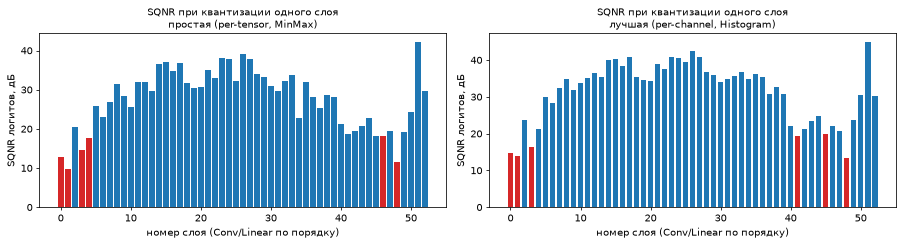

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), dpi=70)
for ax, (cfg_name, df) in zip(axes, sens.items()):
    order = df.set_index("слой").loc[layer_names]
    ax.bar(range(len(order)), order["SQNR, дБ"], color=["C3" if v < df["SQNR, дБ"].iloc[5] + 1e-9 else "C0" for v in order["SQNR, дБ"]])
    ax.set_title(f"SQNR при квантизации одного слоя\n{cfg_name}", fontsize=10)
    ax.set_xlabel("номер слоя (Conv/Linear по порядку)")
    ax.set_ylabel("SQNR логитов, дБ")
plt.tight_layout()
plt.show()

Оставим k слоёв с наименьшим SQNR в FP32 и измерим точность на тестовой выборке.

In [10]:
mixed_rows, mixed_models = [], {}
for cfg_name, qc in QCONFIGS.items():
    for k in [0, 1, 3, 5, 10]:
        skip = sens[cfg_name]["слой"].head(k).tolist()
        qmap = QConfigMapping().set_global(qc)
        for name in skip:
            qmap.set_module_name(name, None)
        qm = ptq(qmap, n_calib=256)
        acc, s = evaluate(qm)
        mixed_models[(cfg_name, k)] = qm
        mixed_rows.append({"Конфигурация": cfg_name, "float-слоёв (k)": k, "Top-1, %": acc,
                           "Δ, п.п.": acc - FP32_ACC, "SQNR логитов, дБ": s, "Размер, МБ": model_size_mb(qm)})
mixed_df = pd.DataFrame(mixed_rows)
mixed_df.round(2)

,Конфигурация,float-слоёв (k),"Top-1, %","Δ, п.п.","SQNR логитов, дБ","Размер, МБ"
0,"простая (per-tensor, MinMax)",0,63.24,-15.57,2.06,3.45
1,"простая (per-tensor, MinMax)",1,64.41,-14.39,2.46,3.45
2,"простая (per-tensor, MinMax)",3,65.04,-13.76,2.53,3.89
3,"простая (per-tensor, MinMax)",5,64.59,-14.22,2.53,3.90
4,"простая (per-tensor, MinMax)",10,65.45,-13.35,2.64,5.09
5,"лучшая (per-channel, Histogram)",0,71.52,-7.29,3.95,3.75
6,"лучшая (per-channel, Histogram)",1,71.46,-7.34,3.95,4.18
7,"лучшая (per-channel, Histogram)",3,73.02,-5.78,3.97,4.18
8,"лучшая (per-channel, Histogram)",5,73.38,-5.43,3.97,4.44
9,"лучшая (per-channel, Histogram)",10,72.48,-6.32,3.98,5.73


PyTorch на CPU

Задержка — медиана 50 замеров на батче 1. Пропускная способность измеряется на батче 32. Используются 6 потоков CPU.

In [11]:
@torch.inference_mode()
def bench_cpu(fn, bs, iters=50, warmup=10):
    x = torch.randn(bs, 3, 224, 224)
    for _ in range(warmup):
        fn(x)
    times = []
    for _ in range(iters):
        t0 = time.perf_counter()
        fn(x)
        times.append(time.perf_counter() - t0)
    return float(np.median(times)) * 1000

def full_metrics(name, fn, size_mb, logits, backend):
    lat = bench_cpu(fn, 1)
    thr = 32 / (bench_cpu(fn, 32, iters=15, warmup=3) / 1000)
    return {"Вариант": name, "Backend": backend, "Top-1, %": top1(logits, y_test),
            "Δ, п.п.": top1(logits, y_test) - FP32_ACC, "SQNR, дБ": sqnr(fp32_test_logits, logits),
            "Latency bs=1, мс": lat, "Throughput bs=32, img/s": thr, "Размер, МБ": size_mb}

from torch.ao.quantization import quantize_dynamic
dyn_model = quantize_dynamic(copy.deepcopy(float_model), {nn.Linear}, dtype=torch.qint8)

best_k = int(mixed_df[mixed_df["Конфигурация"].str.startswith("лучшая")].sort_values("Top-1, %", ascending=False)["float-слоёв (k)"].iloc[0])
simple_k = int(mixed_df[mixed_df["Конфигурация"].str.startswith("простая")].sort_values("Top-1, %", ascending=False)["float-слоёв (k)"].iloc[0])
cpu_candidates = [
    ("FP32", float_model),
    ("Dynamic int8 (только Linear)", dyn_model),
    ("PTQ int8, простая, без sensitivity", mixed_models[("простая (per-tensor, MinMax)", 0)]),
    (f"PTQ int8, простая, sensitivity (k={simple_k} float)", mixed_models[("простая (per-tensor, MinMax)", simple_k)]),
    ("PTQ int8, лучшая, без sensitivity", mixed_models[("лучшая (per-channel, Histogram)", 0)]),
    (f"PTQ int8, лучшая, sensitivity (k={best_k} float)", mixed_models[("лучшая (per-channel, Histogram)", best_k)]),
]
summary_rows = []
for name, m in cpu_candidates:
    logits = fp32_test_logits if m is float_model else predict(m, X_test)
    summary_rows.append(full_metrics(name, m, model_size_mb(m), logits, "PyTorch CPU"))
    print(f"{name}: готово")
pd.DataFrame(summary_rows).round(2)

FP32: готово


Dynamic int8 (только Linear): готово


PTQ int8, простая, без sensitivity: готово


PTQ int8, простая, sensitivity (k=10 float): готово


PTQ int8, лучшая, без sensitivity: готово


PTQ int8, лучшая, sensitivity (k=5 float): готово


,Вариант,Backend,"Top-1, %","Δ, п.п.","SQNR, дБ","Latency bs=1, мс","Throughput bs=32, img/s","Размер, МБ"
0,FP32,PyTorch CPU,78.80,0.00,inf,19.96,97.82,13.60
1,Dynamic int8 (только Linear),PyTorch CPU,78.70,-0.10,40.22,19.08,103.87,9.94
2,"PTQ int8, простая, без sensitivity",PyTorch CPU,63.24,-15.57,2.06,10.23,293.53,3.45
3,"PTQ int8, простая, sensitivity (k=10 float)",PyTorch CPU,65.45,-13.35,2.64,13.48,209.90,5.09
4,"PTQ int8, лучшая, без sensitivity",PyTorch CPU,71.52,-7.29,3.95,10.49,272.29,3.75
5,"PTQ int8, лучшая, sensitivity (k=5 float)",PyTorch CPU,73.38,-5.43,3.97,11.56,221.14,4.44


ONNX Runtime на CPU

Сравним FP32, динамическую INT8 и две статические схемы INT8. Обе статические модели откалиброваны на 256 изображениях. В симметричной модели для TensorRT смещения оставлены в FP32.

In [12]:
import onnx
import onnxruntime as ort
from onnxruntime.quantization import (
    quantize_dynamic as ort_quantize_dynamic, quantize_static, QuantType, QuantFormat,
    CalibrationDataReader, CalibrationMethod,
)
from onnxruntime.quantization.shape_inference import quant_pre_process

ONNX_DIR = Path("onnx_models"); ONNX_DIR.mkdir(exist_ok=True)
fp32_onnx = ONNX_DIR / "mobilenet_v2_fp32.onnx"
torch.onnx.export(float_model, EXAMPLE_INPUTS, str(fp32_onnx), input_names=["input"], output_names=["logits"],
                  dynamic_axes={"input": {0: "batch"}, "logits": {0: "batch"}}, opset_version=17, dynamo=False)
prep_onnx = ONNX_DIR / "mobilenet_v2_fp32_prep.onnx"
quant_pre_process(str(fp32_onnx), str(prep_onnx))

class CalibReader(CalibrationDataReader):
    def __init__(self, n=256, bs=32):
        self.batches = iter([{"input": to_float(X_calib[i:i + bs]).numpy()} for i in range(0, n, bs)])
    def get_next(self):
        return next(self.batches, None)

dyn_onnx = ONNX_DIR / "mobilenet_v2_dynamic_int8.onnx"
ort_quantize_dynamic(str(prep_onnx), str(dyn_onnx), weight_type=QuantType.QInt8)

static_onnx = ONNX_DIR / "mobilenet_v2_static_int8_u8s8.onnx"
quantize_static(str(prep_onnx), str(static_onnx), CalibReader(), quant_format=QuantFormat.QDQ, per_channel=True,
                activation_type=QuantType.QUInt8, weight_type=QuantType.QInt8, calibrate_method=CalibrationMethod.MinMax)

static_sym_onnx = ONNX_DIR / "mobilenet_v2_static_int8_s8s8_sym.onnx"
quantize_static(str(prep_onnx), str(static_sym_onnx), CalibReader(), quant_format=QuantFormat.QDQ, per_channel=True,
                activation_type=QuantType.QInt8, weight_type=QuantType.QInt8, calibrate_method=CalibrationMethod.MinMax,
                extra_options={"ActivationSymmetric": True, "WeightSymmetric": True, "QuantizeBias": False})
for p in [fp32_onnx, dyn_onnx, static_onnx, static_sym_onnx]:
    print(f"{p.name}: {p.stat().st_size / 2**20:.2f} MB")

mobilenet_v2_fp32.onnx: 13.34 MB
mobilenet_v2_dynamic_int8.onnx: 3.51 MB
mobilenet_v2_static_int8_u8s8.onnx: 3.72 MB
mobilenet_v2_static_int8_s8s8_sym.onnx: 3.60 MB


In [13]:
def ort_session(path):
    so = ort.SessionOptions()
    so.intra_op_num_threads = NUM_THREADS
    so.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_ALL
    sess = ort.InferenceSession(str(path), so, providers=["CPUExecutionProvider"])
    return lambda x: sess.run(None, {"input": x.numpy()})[0]

for name, path in [("ONNX FP32", fp32_onnx), ("ONNX dynamic int8", dyn_onnx),
                   ("ONNX static int8 QDQ (u8/s8)", static_onnx), ("ONNX static int8 QDQ (s8/s8 sym)", static_sym_onnx)]:
    fn = ort_session(path)
    summary_rows.append(full_metrics(name, fn, path.stat().st_size / 2**20, predict(fn, X_test), "ONNX Runtime CPU"))
    print(f"{name}: готово")
cpu_df = pd.DataFrame(summary_rows)
cpu_df.round(2)

ONNX FP32: готово


ONNX dynamic int8: готово


ONNX static int8 QDQ (u8/s8): готово


ONNX static int8 QDQ (s8/s8 sym): готово


,Вариант,Backend,"Top-1, %","Δ, п.п.","SQNR, дБ","Latency bs=1, мс","Throughput bs=32, img/s","Размер, МБ"
0,FP32,PyTorch CPU,78.80,0.00,inf,19.96,97.82,13.60
1,Dynamic int8 (только Linear),PyTorch CPU,78.70,-0.10,40.22,19.08,103.87,9.94
2,"PTQ int8, простая, без sensitivity",PyTorch CPU,63.24,-15.57,2.06,10.23,293.53,3.45
3,"PTQ int8, простая, sensitivity (k=10 float)",PyTorch CPU,65.45,-13.35,2.64,13.48,209.90,5.09
4,"PTQ int8, лучшая, без sensitivity",PyTorch CPU,71.52,-7.29,3.95,10.49,272.29,3.75
5,"PTQ int8, лучшая, sensitivity (k=5 float)",PyTorch CPU,73.38,-5.43,3.97,11.56,221.14,4.44
6,ONNX FP32,ONNX Runtime CPU,78.80,0.00,119.04,3.73,364.95,13.34
7,ONNX dynamic int8,ONNX Runtime CPU,77.71,-1.10,11.42,78.34,12.88,3.51
8,ONNX static int8 QDQ (u8/s8),ONNX Runtime CPU,68.69,-10.11,7.10,3.11,395.83,3.72
9,ONNX static int8 QDQ (s8/s8 sym),ONNX Runtime CPU,69.27,-9.53,6.04,11.75,102.08,3.60


TensorRT на RTX A6000

Для FP32 и FP16 используем ONNX-модели соответствующей точности, для INT8 — симметричную модель QDQ. Размер TensorRT-модели считаем по сериализованному движку. Для TensorRT и PyTorch на GPU измеряем задержку на батче 1 и пропускную способность на батче 32.

In [14]:
import tensorrt as trt
print("TensorRT", trt.__version__)
TRT_LOGGER = trt.Logger(trt.Logger.ERROR)

def build_engine(onnx_path, precision):
    builder = trt.Builder(TRT_LOGGER)
    network = builder.create_network(0)
    parser = trt.OnnxParser(network, TRT_LOGGER)
    assert parser.parse_from_file(str(onnx_path)), [str(parser.get_error(i)) for i in range(parser.num_errors)]
    config = builder.create_builder_config()
    config.set_memory_pool_limit(trt.MemoryPoolType.WORKSPACE, 4 << 30)
    profile = builder.create_optimization_profile()
    profile.set_shape("input", (1, 3, 224, 224), (32, 3, 224, 224), (64, 3, 224, 224))
    config.add_optimization_profile(profile)
    return bytes(builder.build_serialized_network(network, config))

class TRTModel:
    def __init__(self, engine_bytes):
        self.engine = trt.Runtime(TRT_LOGGER).deserialize_cuda_engine(engine_bytes)
        self.ctx = self.engine.create_execution_context()
        to_torch = {trt.DataType.FLOAT: torch.float32, trt.DataType.HALF: torch.float16}
        self.in_dtype = to_torch[self.engine.get_tensor_dtype("input")]
        self.out_dtype = to_torch[self.engine.get_tensor_dtype("logits")]
    def __call__(self, x):
        x = x.cuda().to(self.in_dtype).contiguous()
        out = torch.empty((x.shape[0], 1000), device="cuda", dtype=self.out_dtype)
        self.ctx.set_input_shape("input", tuple(x.shape))
        self.ctx.set_tensor_address("input", x.data_ptr())
        self.ctx.set_tensor_address("logits", out.data_ptr())
        self.ctx.execute_async_v3(torch.cuda.current_stream().cuda_stream)
        return out.float()

@torch.inference_mode()
def bench_gpu(fn, bs, iters=100, warmup=20):
    x = torch.randn(bs, 3, 224, 224, device="cuda")
    for _ in range(warmup):
        fn(x)
    torch.cuda.synchronize()
    times = []
    for _ in range(iters):
        t0 = time.perf_counter()
        fn(x)
        torch.cuda.synchronize()
        times.append(time.perf_counter() - t0)
    return float(np.median(times)) * 1000

gpu_fp32 = copy.deepcopy(float_model).cuda().eval()
gpu_fp16 = copy.deepcopy(float_model).cuda().half().eval()
gpu_candidates = [
    ("PyTorch CUDA FP32", lambda x: gpu_fp32(x.cuda()), model_size_mb(float_model)),
    ("PyTorch CUDA FP16", lambda x: gpu_fp16(x.cuda().half()), model_size_mb(gpu_fp16)),
]
fp16_onnx = ONNX_DIR / "mobilenet_v2_fp16.onnx"
torch.onnx.export(gpu_fp16, (torch.randn(1, 3, 224, 224, device="cuda", dtype=torch.float16),), str(fp16_onnx),
                  input_names=["input"], output_names=["logits"],
                  dynamic_axes={"input": {0: "batch"}, "logits": {0: "batch"}}, opset_version=17, dynamo=False)
for precision, path in [("fp32", fp32_onnx), ("fp16", fp16_onnx), ("int8", static_sym_onnx)]:
    t0 = time.time()
    eng = build_engine(path, precision)
    gpu_candidates.append((f"TensorRT {precision.upper()}", TRTModel(eng), len(eng) / 2**20))
    print(f"TensorRT {precision}: engine собран за {time.time() - t0:.0f}s")

gpu_rows = []
for name, fn, size in gpu_candidates:
    logits = predict(fn, X_test)
    gpu_rows.append({"Вариант": name, "Top-1, %": top1(logits, y_test), "Δ, п.п.": top1(logits, y_test) - FP32_ACC,
                     "SQNR, дБ": sqnr(fp32_test_logits, logits), "Latency bs=1, мс": bench_gpu(fn, 1),
                     "Throughput bs=32, img/s": 32 / (bench_gpu(fn, 32) / 1000), "Размер, МБ": size})
gpu_df = pd.DataFrame(gpu_rows)
gpu_df.round(2)

TensorRT 11.5.0.63


TensorRT fp32: engine собран за 54s


TensorRT fp16: engine собран за 55s


TensorRT int8: engine собран за 73s


,Вариант,"Top-1, %","Δ, п.п.","SQNR, дБ","Latency bs=1, мс","Throughput bs=32, img/s","Размер, МБ"
0,PyTorch CUDA FP32,78.75,-0.05,57.78,11.85,2731.51,13.60
1,PyTorch CUDA FP16,78.85,0.05,47.09,12.17,2703.73,6.85
2,TensorRT FP32,78.78,-0.03,59.63,1.35,8165.02,13.79
3,TensorRT FP16,78.90,0.10,43.85,1.66,13194.63,7.08
4,TensorRT INT8,78.22,-0.59,10.02,1.67,18021.30,4.42


Результаты

In [15]:
print("=== Гиперпараметры PTQ (PyTorch FX, CPU) ===")
print(hp_df.round(2).to_string(index=False))
print("\n=== Sensitivity / mixed precision ===")
print(mixed_df.round(2).to_string(index=False))
print("\n=== CPU: скорость / качество / размер ===")
print(cpu_df.round(2).to_string(index=False))
print("\n=== GPU (RTX A6000): скорость / качество / размер ===")
print(gpu_df.round(2).to_string(index=False))

=== Гиперпараметры PTQ (PyTorch FX, CPU) ===
       Группа          Конфигурация  Top-1, %  Δ, п.п.  SQNR логитов, дБ
            —                  FP32     78.80     0.00               inf
observer акт.                MinMax     65.38   -13.43              2.86
observer акт.   MovingAverageMinMax     70.50    -8.31              4.12
observer акт.             Histogram     71.52    -7.29              3.95
   схема акт. symmetric (Histogram)     55.39   -23.41              3.51
         веса  per-tensor symmetric     68.10   -10.70              2.59
         веса     per-tensor affine     71.59    -7.21              3.79
         веса    per-channel affine     71.31    -7.49              3.79
   калибровка            8 картинок     77.38    -1.43              9.14
   калибровка           32 картинки     74.45    -4.36              4.79
   калибровка          128 картинок     74.80    -4.00              6.48
   калибровка          512 картинок     71.92    -6.88              5.41

=== S

В PyTorch на CPU точность выросла с 71,5% до 73,4%, когда пять самых чувствительных слоёв оставили в FP32. На A6000 при батче 32 TensorRT в INT8 обрабатывал в 2,2 раза больше изображений в секунду, чем в FP32, при этом точность снизилась с 78,8% до 78,2%.